<a href="https://colab.research.google.com/github/vivianagonzalez203/Bootcamp-Data-Science/blob/main/04_Machine%20Learning/Clase_20_Machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introducción a Machine Learning


## 1. ¿Qué es Machine Learning?

Machine Learning (ML) es una rama de la inteligencia artificial donde los sistemas aprenden patrones a partir de datos para realizar predicciones o tomar decisiones sin ser programados explícitamente.

https://www.linkedin.com/pulse/what-artificial-intelligence-its-most-important-islam-abdelnaser-ohxif/

## 2. Tipos de Aprendizaje

### 2.1 Aprendizaje Supervisado
Se utiliza un conjunto de datos etiquetados para entrenar el modelo. (ej: clasificación, regresión)

**Ejemplo Práctico:** Clasificación de Flores Iris

**EJEMPLO SUPERVISADO**

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Crear un dataset con más registros
data = {
    'Peso': [5.0, 5.2, 4.9, 3.8, 3.5, 3.2, 3.0, 5.1, 5.3, 3.6, 3.7, 3.4],
    'Energía': [8, 7, 6, 5, 4, 3, 2, 9, 6, 3, 4, 2],
    'Animal': ['Perro', 'Perro', 'Perro', 'Gato', 'Gato', 'Gato', 'Gato', 'Perro', 'Perro', 'Gato', 'Gato', 'Gato']
}

df = pd.DataFrame(data)

# 2. Separar características y etiquetas
X = df[['Peso', 'Energía']]
y = df['Animal']

# 3. Dividir los datos (con stratify para mantener proporciones)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)

# 4. Modelo KNN con 3 vecinos
modelo = KNeighborsClassifier(n_neighbors=3)
modelo.fit(X_train, y_train)

# 5. Predicción y evaluación
y_pred = modelo.predict(X_test)
print("Precisión del modelo:", accuracy_score(y_test, y_pred))

# 6. Mostrar predicciones
print("\nComparación Real vs Predicción:")
print(pd.DataFrame({'Real': y_test.values, 'Predicción': y_pred}))



Precisión del modelo: 1.0

Comparación Real vs Predicción:
    Real Predicción
0  Perro      Perro
1   Gato       Gato
2  Perro      Perro
3   Gato       Gato


### 2.2 Aprendizaje No Supervisado
Se trabaja con datos no etiquetados y se busca descubrir patrones o estructuras subyacentes. (ej: clustering)

**Ejemplo Práctico:** Clustering con K-Means

In [ ]:
from sklearn.cluster import KMeans

# Crear clusters
kmeans = KMeans(n_clusters=3)
X = kmeans.fit(iris.data)

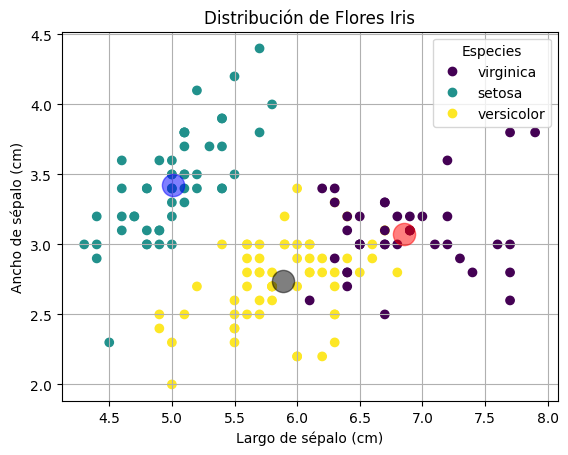

In [ ]:
# Visualización
plt.scatter(iris.data[:, 0], iris.data[:, 1], c=X.labels_)
plt.plot(kmeans.cluster_centers_[0][0], kmeans.cluster_centers_[0][1], 'ro',markersize=16, alpha = 0.5)
plt.plot(kmeans.cluster_centers_[1][0], kmeans.cluster_centers_[1][1], 'bo',markersize=16, alpha = 0.5)
plt.plot(kmeans.cluster_centers_[2][0], kmeans.cluster_centers_[2][1], 'ko',markersize=16, alpha = 0.5)
plt.grid()
plt.xlabel('Largo de sépalo (cm)')
plt.ylabel('Ancho de sépalo (cm)')

# Añadir leyenda usando los target_names
plt.legend(handles=scatter.legend_elements()[0],
           title="Especies",
           labels=['virginica','setosa','versicolor'])

plt.xlabel('Largo de sépalo (cm)')
plt.ylabel('Ancho de sépalo (cm)')
plt.title('Distribución de Flores Iris')
plt.show()

### 2.3 Aprendizaje por Refuerzo
El agente aprende a través de la interacción con el entorno, tomando decisiones y recibiendo recompensas o penalizaciones.

**Ejemplo:** https://www.youtube.com/watch?v=L_4BPjLBF4E

## 3. Diferencias con Automatización Tradicional

- **Machine Learning:** Aprende patrones a partir de datos, lo que permite adaptarse y mejorar con el tiempo.
- **Automatización:** Sigue reglas y procedimientos predefinidos sin capacidad de adaptación.




 | Machine Learning | Automatización Tradicional |
 |------------------|----------------------------|
 | Aprende de datos | Sigue reglas predefinidas |
 | Adaptable        | Estático                  |
 | Maneja complejidad | Tareas estructuradas   |

**Tipos de automatización más comunes en el mundo laboral**

| **Tipo de Automatización**           | **Descripción**                                      | **Casos de Uso Típicos**                                |
| ------------------------------------ | ---------------------------------------------------- | ------------------------------------------------------- |
| **RPA (Robotic Process Automation)** | Automatiza tareas repetitivas usando "bots" software | Procesamiento de facturas, migración de datos           |
| **Workflow Automation**              | Orquesta procesos entre múltiples sistemas           | Aprobaciones, onboarding, flujos documentales           |
| **Data Processing Automation**       | Manejo automático de grandes volúmenes de datos      | Reportes financieros, limpieza de bases de datos        |
| **IT Process Automation**            | Gestión de infraestructura y sistemas                | Provisionamiento de servidores, backups                 |
| **Customer Service Automation**      | Automatización de interacciones con clientes         | Chatbots, respuestas automáticas, routing de tickets    |
| **Marketing Automation**             | Gestión automatizada de campañas y leads             | Email marketing, segmentación de audiencias             |
| **HR Automation**                    | Optimización de procesos de recursos humanos         | Nóminas, reclutamiento, evaluación de desempeño<br><br> |

**Ejemplo Automatización revisión del clima**

In [ ]:
import requests
API_KEY = 'c4adf9f47521461eb6c202448252703'
ciudad_a_consultar = 'Medellin'

x = requests.get('https://api.weatherapi.com/v1/current.json?q='+ciudad_a_consultar+'&key='+API_KEY)
print(x.status_code)

200


In [ ]:
import json

my_json = x.content.decode('utf8').replace("'", '"')
data = json.loads(my_json)
s = json.dumps(data, indent=4, sort_keys=True)
print(s)

{
    "current": {
        "chance_of_rain": 100,
        "chance_of_snow": 0,
        "cloud": 81,
        "condition": {
            "code": 1063,
            "icon": "//cdn.weatherapi.com/weather/64x64/night/176.png",
            "text": "Patchy rain nearby"
        },
        "dewpoint_c": 14.1,
        "dewpoint_f": 57.3,
        "feelslike_c": 15.1,
        "feelslike_f": 59.3,
        "gust_kph": 11.3,
        "gust_mph": 7.0,
        "heatindex_c": 15.1,
        "heatindex_f": 59.3,
        "humidity": 93,
        "is_day": 0,
        "last_updated": "2026-05-20 19:15",
        "last_updated_epoch": 1779322500,
        "precip_in": 0.02,
        "precip_mm": 0.59,
        "pressure_in": 29.93,
        "pressure_mb": 1014.0,
        "temp_c": 15.1,
        "temp_f": 59.3,
        "uv": 0.0,
        "vis_km": 9.0,
        "vis_miles": 5.0,
        "will_it_rain": 1,
        "will_it_snow": 0,
        "wind_degree": 92,
        "wind_dir": "E",
        "wind_kph": 5.4,
        "wi

In [ ]:
print(data['current']['temp_c'])

15.1


**Ejemplo Comparativo:** Detección de Spam

**Automático:** Reglas basadas en palabras clave



In [ ]:
def spam_detector(email):
    spam_words = ['oferta', 'dinero', 'gratis','rápido']
    return any(word in email.lower() for word in spam_words)

In [ ]:
spam_detector("¡Eres el ganador!")

False

**Machine Learning:** Clasificación aprendida de ejemplos

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
import pandas as pd

In [ ]:
# Datos de ejemplo
emails = ["Gana dinero rapido", "Reunion importante mañana", "Oferta exclusiva para ti"]
labels = [1, 0, 1]  # 1 = spam, 0 = no spam

labels_df = pd.DataFrame(labels,columns=['Es Spam?'])

In [ ]:
# Preprocesamiento
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(emails)
X_df = pd.DataFrame(X.todense(), columns = vectorizer.get_feature_names_out())
pd.concat([X_df,labels_df],axis=1)

,dinero,exclusiva,gana,importante,mañana,oferta,para,rapido,reunion,ti,Es Spam?
0,1,0,1,0,0,0,0,1,0,0,1
1,0,0,0,1,1,0,0,0,1,0,0
2,0,1,0,0,0,1,1,0,0,1,1


In [ ]:
# Entrenar modelo
clf = MultinomialNB()
clf.fit(X, labels)

MultinomialNB()

In [ ]:
# Predecir
test_email = ["¡Eres el ganador!"]
print("Predicción:", clf.predict(vectorizer.transform(test_email))[0])

Predicción: 1


## 4. Aplicaciones Reales

1. **Recomendación de Contenido** (Netflix, Spotify)
2. **Vehículos Autónomos** (Tesla, Waymo)
3. **Diagnóstico Médico** (Análisis de imágenes médicas)
4. **Chatbots** (GPT, Bard)
5. **Detección de Fraudes** (Sistemas bancarios)

**Demo Rápida:** Reconocimiento de Dígitos (MNIST)


In [ ]:
from sklearn.datasets import load_digits
from sklearn.svm import SVC

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target

In [ ]:
model = SVC()
model.fit(X[:1000], y[:1000])  # Usar subset para velocidad

SVC()

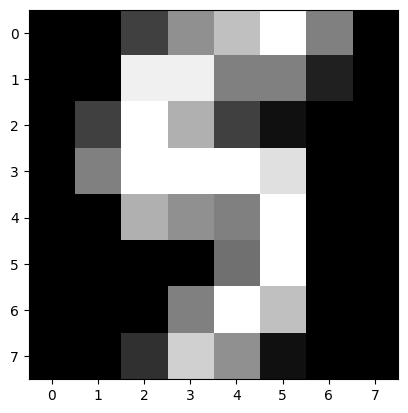

In [ ]:
# Predicción de ejemplo
import matplotlib.pyplot as plt
test = 1700
plt.imshow(digits.images[test], cmap='gray')


In [ ]:
digits.images[test]

array([[ 0.,  0.,  4.,  9., 12., 16.,  8.,  0.],
       [ 0.,  0., 15., 15.,  8.,  8.,  2.,  0.],
       [ 0.,  4., 16., 11.,  4.,  1.,  0.,  0.],
       [ 0.,  8., 16., 16., 16., 14.,  0.,  0.],
       [ 0.,  0., 11.,  9.,  8., 16.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  7., 16.,  0.,  0.],
       [ 0.,  0.,  0.,  8., 16., 12.,  0.,  0.],
       [ 0.,  0.,  3., 13.,  9.,  1.,  0.,  0.]])

In [ ]:
print("Predicción:", model.predict([digits.data[test]])[0])
plt.show()

Predicción: 5
